In [76]:
import panel as pn
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import os
from scipy.optimize import curve_fit
import pickle
import re
import numpy as np

### Load Data into dfs

In [16]:
name = "ygrad_yeddy_extra"

In [57]:
with open(f"{name}.pkl", "rb") as f:
    dict_data = pickle.load(f)

dict_data.keys()

items = list(dict_data.items())

dict_1 = dict(items[:8])
dict_2 = dict(items[8:24])
dict_3 = dict(items[24:])

dict_list = [dict_1, dict_2, dict_3]

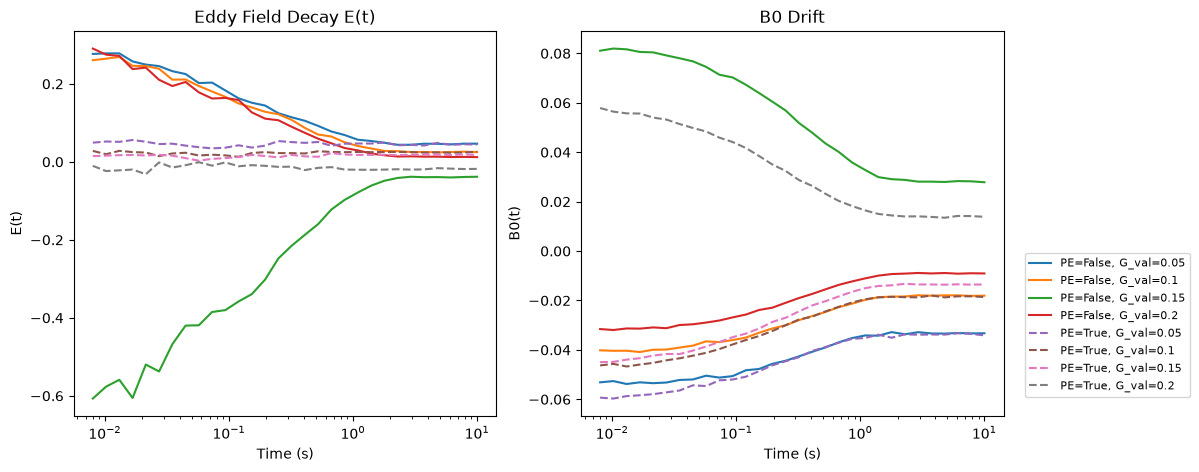

<Figure size 640x480 with 0 Axes>

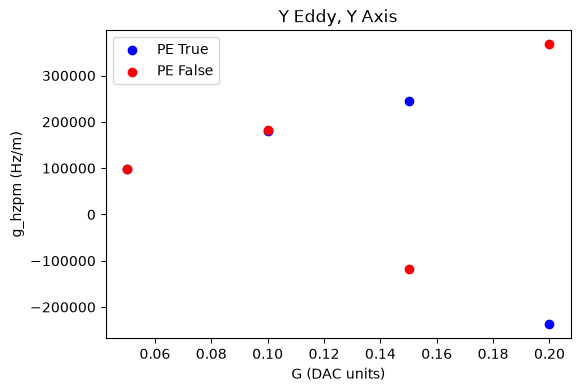

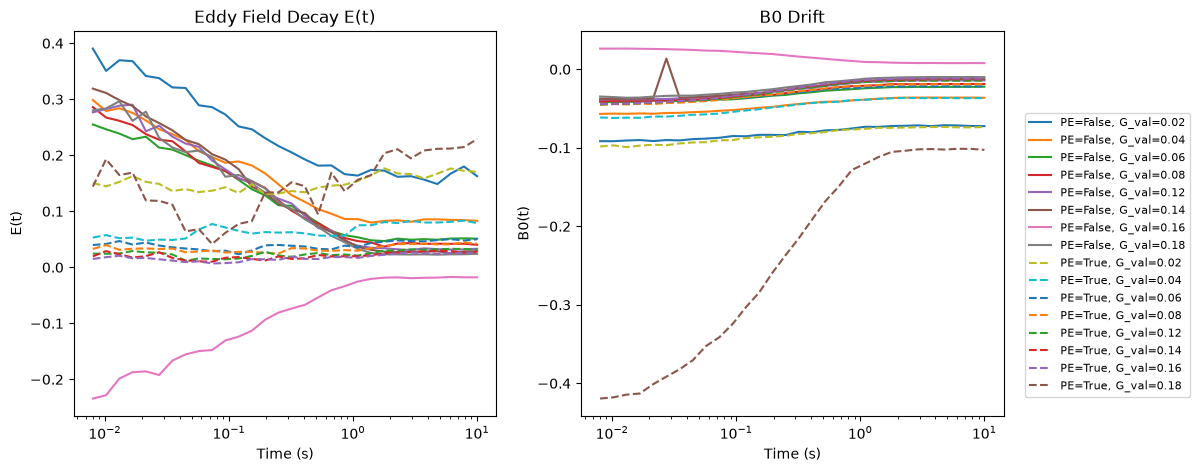

<Figure size 640x480 with 0 Axes>

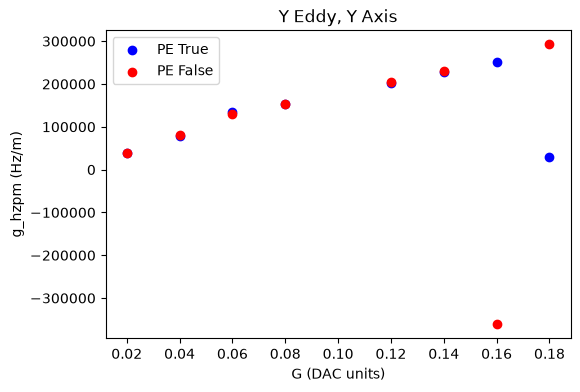

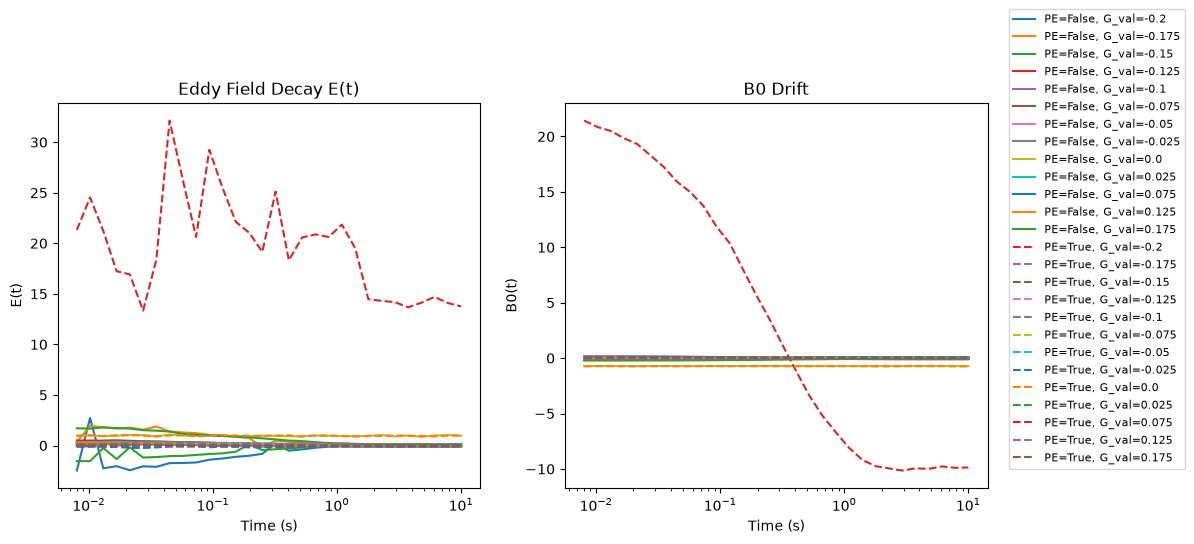

<Figure size 640x480 with 0 Axes>

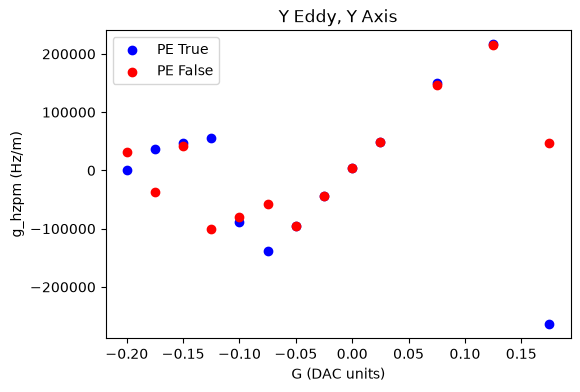

In [80]:
for dict_ in dict_list:
    g_h = []
    g_vals = []
    pe_vals = []
    be_vals = []
    f_list = []
    labels = []
    g_hzpm_list = []
    for key, value in dict_.items():
    
        match = re.search(r'G(-?\d*\.?\d+)$', key)
        if match is None:
            continue
            
        pe = "PETrue" in key
        be = "BETrue" in key
        g = float(match.group(1))
        
        g_vals.append(g)
        g_h.append(dict_[key]["g_hzpm"])
        pe_vals.append(pe)
        be_vals.append(be)
        f_list.append(value["freq"])
        labels.append(f"PE={pe}, G_val={g}")
        # print(key, ": ", dict_[key]["g_hzpm"])
    
    df_ghzpm = pd.DataFrame({"G": g_vals, "g_hzpm (Hz/m)": g_h, "PE": pe_vals, "BE": be_vals})
    # display(df_ghzpm)
    g_hzpm_list.append(df_ghzpm)

    # colours = [ "blue", "cornflowerblue", "orange", "gold", "green", "limegreen", "red", "salmon"]
    colours = [
        "blue", 
        "orange", 
        "green", 
        "red", "cornflowerblue","gold", "limegreen","salmon",
    
    ]
    # colours = [ "blue", "red"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig2 = plt.figure()
    
    for df, label in zip(f_list, labels):
        if "PE=True" in label:
            axes[0].plot(df["times (s)"][1:], df["E(t)"][1:], label=label, linestyle = "--")
    
        else:
            axes[0].plot(df["times (s)"][1:], df["E(t)"][1:], label=label)
    
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("E(t)")
    axes[0].set_title("Eddy Field Decay E(t)")
    # axes[0].legend(fontsize=8)
    
    for df, label in zip(f_list, labels):
        if "PE=True" in label:
            axes[1].plot(df["times (s)"][1:], df["B0(t)"][1:], label=label, linestyle = "--")
    
        else:
            axes[1].plot(df["times (s)"][1:], df["B0(t)"][1:], label=label)
    
    
    axes[1].set_xscale("log")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("B0(t)")
    axes[1].set_title("B0 Drift")
    axes[1].legend(loc = (1.05, 0.05),fontsize=8)
    
    plt.suptitle(name)
    plt.tight_layout()
    plt.show() 

    
    mask = np.array(pe_vals) # mask for PE on or off
    
    plt.figure(figsize=(6,4))
    plt.scatter(np.array(g_vals)[mask], np.array(g_h)[mask], color="blue", label="PE True")
    plt.scatter(np.array(g_vals)[~mask], np.array(g_h)[~mask], color="red", label="PE False")
    
    plt.xlabel("G (DAC units)")
    plt.ylabel("g_hzpm (Hz/m)")
    plt.title("Y Eddy, Y Axis")
    plt.legend()
    plt.show()

### Plot E(t) / B0(t)

In [83]:
df_ghzpm = pd.concat(g_hzpm_list, ignore_index=True)

Slope: 1796934.8659003826
Intercept: 0.0


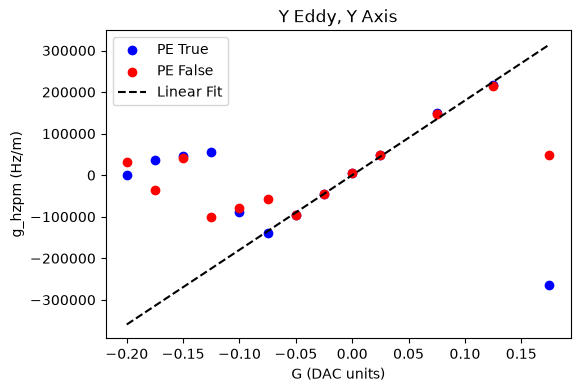

In [84]:
from sklearn.linear_model import LinearRegression

val1 = -0.05
val2 = 0.15
df_fit = df_ghzpm[(df_ghzpm["G"] > val1) & (df_ghzpm["G"] < val2)]
X = df_fit[["G"]]
Y = df_fit["g_hzpm (Hz/m)"]

# Force intercept to 0 by setting fit_intercept=False
model = LinearRegression(fit_intercept=False)
model.fit(X, Y)

# Get the slope
slope = model.coef_[0]

print(f"Slope: {slope}")           # e.g., ~2.0
print(f"Intercept: {model.intercept_}") # Strictly 0.0

x_fit = np.linspace(df_ghzpm[["G"]].min(), df_ghzpm[["G"]].max(), 100)


mask = np.array(pe_vals) # mask for PE on or off

plt.figure(figsize=(6,4))
plt.scatter(np.array(g_vals)[mask], np.array(g_h)[mask], color="blue", label="PE True")
plt.scatter(np.array(g_vals)[~mask], np.array(g_h)[~mask], color="red", label="PE False")
plt.plot(x_fit, slope*x_fit + b, 'k--', label=f"Linear Fit")

plt.xlabel("G (DAC units)")
plt.ylabel("g_hzpm (Hz/m)")
plt.title("Y Eddy, Y Axis")
plt.legend()
plt.show()